# National Cultural Heritage Laws — Exploratory Analysis

Dataset: `mhm001.parquet` — 2,941 national legal instruments (laws, decrees, case-law, agreements) concerning cultural heritage, submitted by UNESCO member states.

## Data source & attribution

- **Source:** [UNESCO DataHub — National Cultural Heritage Laws (`mhm001`)](https://data.unesco.org/explore/assets/mhm001/)
- **Publisher:** UNESCO
- **License:** [Open Access](https://www.unesco.org/en/open-access)
- **Last modified (source):** 2026-09-17
- **Local snapshot used here:** `mhm001.parquet`, 2,941 records

**Description:** An international gateway to national legislation concerning cultural heritage, serving law-enforcement authorities, art-market professionals, academics, and policymakers as an essential reference for determining the legality of cultural property exports, imports, and ownership transfers.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from shapely import wkb

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

## 1. Load the data

In [2]:
df = pd.read_parquet("datasets/mhm001.parquet")
print(df.shape)
df.head()

(2941, 20)


,id,uuid,title_en,terms,countries,date,instrument,categories,year,date_application,date_abrogation,title_fr,title_es,title_ar,title_ru,title_zh,country_title_en,regional_group,geometry,geo_point_2d
0,12510.0,6480bcd2-ebe8-4f10-8aea-50c33bab6cfe,Parochial Libraries Act 1708,Archives,GB,1708-01-01,Case-law,Immovable Cultural property,1708.0,None,None,Loi de 1708 sur les bibliothèques paroissiales,Ley de Bibliotecas Paroquiales 1708,Parochial Libraries Act 1708,Закон о приходских библиотеках 1708,1708年《教区图书馆法》,United Kingdom of Great Britain and Northern I...,Europe and North America,b'\x01\x06\x00\x00\x00\x13\x00\x00\x00\x01\x03...,b'\x01\x01\x00\x00\x00\xb3\x91\xef\xd6\x8aE\n\...
1,12509.0,2641e576-ee09-49c9-a20a-5c2f4fe8f848,Ordre de la Commission nationale des Beaux Art...,Art Market,IT,1820-01-01,Case-law,Movable Cultural Heritage,1820.0,None,None,Ordre de la Commission nationale des Beaux Art...,Orden de la Comisión Nacional de Bellas Artes ...,ترتيب اللجنة الوطنية للفنون الجميلة (1820),Приказ Национальной комиссии изящных искусств ...,国家美术委员会勋章(1820年),Italy,Europe and North America,b'\x01\x06\x00\x00\x00\x03\x00\x00\x00\x01\x03...,b'\x01\x01\x00\x00\x00\xfek\xc6\xdf\xf9\x11(@V...
2,12508.0,94496f8e-c74c-4fad-8a58-6d22a16398ec,Decree No. 47 of 1822 — Ordering that the wor...,None,CO,1822-01-01,Decree,None,1822.0,1822-03-12,None,Décret n° 47 de 1822 — Ordonnant le rassemble...,Decreto No.47 de 1822 — Que ordena reunir a l...,مرسوم رقم 47 يُنص على جمع في المكتبة العامة أع...,"Декрет №47, упорядочивающий размещение в публи...",第47号法令，命令将穆蒂斯主持的植物学考察的著作收录于公共图书馆,Colombia,Latin America and the Caribbean,b'\x01\x03\x00\x00\x00\x01\x00\x00\x00.\x00\x0...,b'\x01\x01\x00\x00\x00\x85\x02\x8c0\xd6ER\xc0b...
3,12665.0,b45c7ddb-395b-4cf7-bd0d-c068e911b34e,Decreto 117,None,CO,1823-01-01,Law,None,1823.0,None,None,Décret 117,Decreto 117,مرسوم 117,Постановление 117,第117号法令,Colombia,Latin America and the Caribbean,b'\x01\x03\x00\x00\x00\x01\x00\x00\x00.\x00\x0...,b'\x01\x01\x00\x00\x00\x85\x02\x8c0\xd6ER\xc0b...
4,12507.0,dcf68675-9547-4199-b00f-d8cc8da73055,Decree No. 106 of 1823 — Establishing a Chair...,None,CO,1823-01-01,Decree,None,1823.0,1823-06-10,None,Décret n° 106 de 1823 — Portant création d'un...,Decreto No. 106 de 1823 — Que establece una C...,مرسوم رقم 106 الذي يؤسس كرسيًا لعلم النبات في ...,"Декрет №106, устанавливающий кафедру ботаники ...",第106号法令：在国家博物馆设立植物学讲座,Colombia,Latin America and the Caribbean,b'\x01\x03\x00\x00\x00\x01\x00\x00\x00.\x00\x0...,b'\x01\x01\x00\x00\x00\x85\x02\x8c0\xd6ER\xc0b...


## 2. Select useable columns for analysis

Drop the per-language title fields (`title_fr`/`es`/`ar`/`ru`/`zh`) and the heavy `geometry` (country boundary polygons) — keep `geo_point_2d` for a lightweight representative location.

In [3]:
USEABLE_COLUMNS = [
    "id",
    "title_en",
    "terms",
    "country_title_en",
    "countries",    
    "regional_group",
    "instrument",
    "categories",
    "year",
    "geo_point_2d",
]

df = df[USEABLE_COLUMNS].rename(columns={"country_title_en": "country","countries": "iso_codes","regional_group": "region","title_en": "law_title_en"})
print(df.shape)
df.head()

(2941, 10)


,id,law_title_en,terms,country,iso_codes,region,instrument,categories,year,geo_point_2d
0,12510.0,Parochial Libraries Act 1708,Archives,United Kingdom of Great Britain and Northern I...,GB,Europe and North America,Case-law,Immovable Cultural property,1708.0,b'\x01\x01\x00\x00\x00\xb3\x91\xef\xd6\x8aE\n\...
1,12509.0,Ordre de la Commission nationale des Beaux Art...,Art Market,Italy,IT,Europe and North America,Case-law,Movable Cultural Heritage,1820.0,b'\x01\x01\x00\x00\x00\xfek\xc6\xdf\xf9\x11(@V...
2,12508.0,Decree No. 47 of 1822 — Ordering that the wor...,None,Colombia,CO,Latin America and the Caribbean,Decree,None,1822.0,b'\x01\x01\x00\x00\x00\x85\x02\x8c0\xd6ER\xc0b...
3,12665.0,Decreto 117,None,Colombia,CO,Latin America and the Caribbean,Law,None,1823.0,b'\x01\x01\x00\x00\x00\x85\x02\x8c0\xd6ER\xc0b...
4,12507.0,Decree No. 106 of 1823 — Establishing a Chair...,None,Colombia,CO,Latin America and the Caribbean,Decree,None,1823.0,b'\x01\x01\x00\x00\x00\x85\x02\x8c0\xd6ER\xc0b...


## 3. Clean `year`

`year` uses `0` as a placeholder for "unknown" — convert it to null instead.

In [4]:
before_valid = df["year"].notna().sum()
df["year"] = df["year"].replace(0, np.nan)
after_valid = df["year"].notna().sum()
print(f"Nulled {before_valid - after_valid} row(s) with a placeholder year of 0; {after_valid} have a known year")

df["year"].describe()

Nulled 45 row(s) with a placeholder year of 0; 2896 have a known year


count    2896.000000
mean     1987.074586
std        25.713083
min      1708.000000
25%      1978.000000
50%      1994.000000
75%      2003.000000
max      2025.000000
Name: year, dtype: float64

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2941 entries, 0 to 2940
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   id            2941 non-null   float64
 1   law_title_en  2941 non-null   object 
 2   terms         1524 non-null   object 
 3   country       2775 non-null   object 
 4   iso_codes     2858 non-null   object 
 5   region        2775 non-null   object 
 6   instrument    2597 non-null   object 
 7   categories    2187 non-null   object 
 8   year          2896 non-null   float64
 9   geo_point_2d  2761 non-null   object 
dtypes: float64(2), object(8)
memory usage: 229.9+ KB


## 4. Missing values

In [6]:
missing_pct = (df.isna().mean() * 100).sort_values(ascending=False)
missing_pct[missing_pct > 0]

terms           48.180891
categories      25.637538
instrument      11.696702
geo_point_2d     6.120367
country          5.644339
region           5.644339
iso_codes        2.822169
year             1.530092
dtype: float64

## 5. Legal instrument types

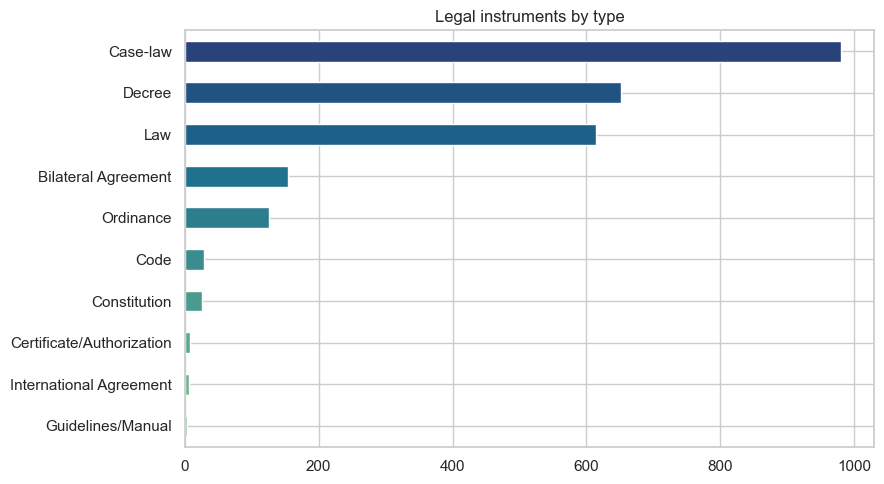

In [7]:
fig, ax = plt.subplots(figsize=(9, 5))
df["instrument"].value_counts().sort_values().plot(kind="barh", ax=ax, color=sns.color_palette("crest", 10))
ax.set_title("Legal instruments by type")
plt.tight_layout()
plt.show()

## 6. Heritage categories covered

`categories` can list more than one value per record (comma-separated), so explode before counting.

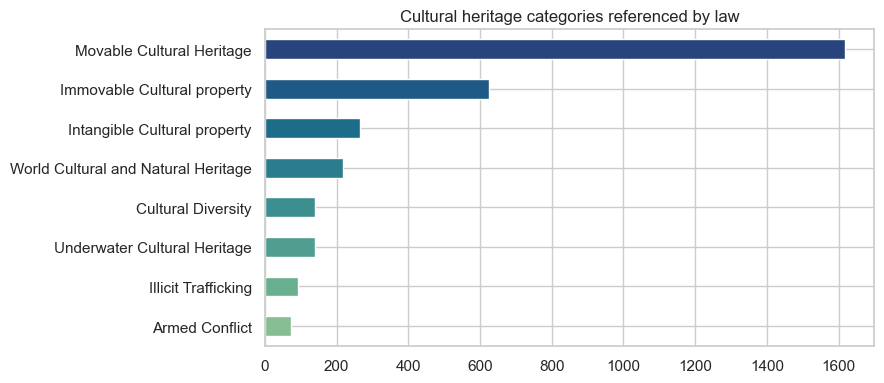

In [8]:
category_counts = df["categories"].dropna().str.split(",").explode().str.strip().value_counts()

fig, ax = plt.subplots(figsize=(9, 4))
category_counts.sort_values().plot(kind="barh", ax=ax, color=sns.color_palette("crest", len(category_counts)))
ax.set_title("Cultural heritage categories referenced by law")
plt.tight_layout()
plt.show()

## 7. Regional distribution

Some records carry a duplicated or multi-valued `regional_group` (e.g. `"Arab States,Arab States"`); dedupe per row before counting.

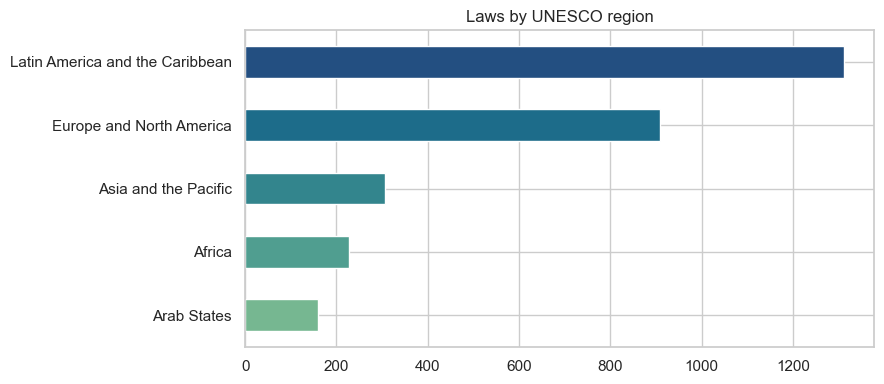

In [9]:
def unique_regions(value):
    if pd.isna(value):
        return np.nan
    return ",".join(dict.fromkeys(part.strip() for part in value.split(",")))

region_counts = df["region"].apply(unique_regions).dropna().str.split(",").explode().value_counts()

fig, ax = plt.subplots(figsize=(9, 4))
region_counts.sort_values().plot(kind="barh", ax=ax, color=sns.color_palette("crest", len(region_counts)))
ax.set_title("Laws by UNESCO region")
plt.tight_layout()
plt.show()

## 8. Laws enacted over time

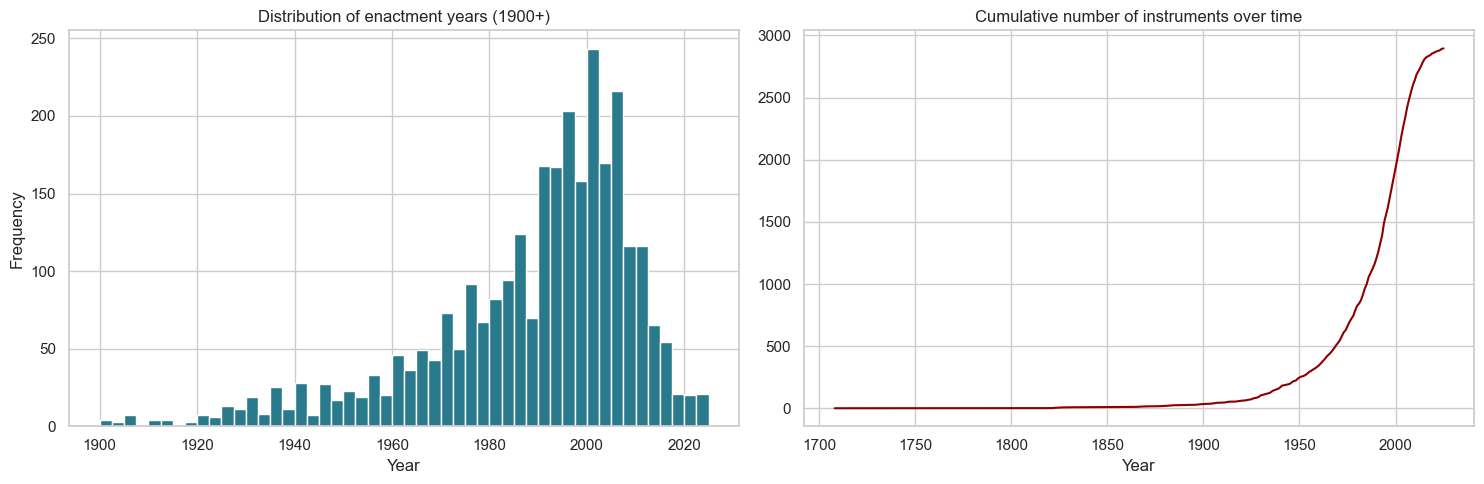

In [10]:
by_year = df["year"].dropna()

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

by_year[by_year >= 1900].plot(kind="hist", bins=50, ax=axes[0], color=sns.color_palette("crest")[3])
axes[0].set_title("Distribution of enactment years (1900+)")
axes[0].set_xlabel("Year")

by_year.value_counts().sort_index().cumsum().plot(ax=axes[1], color="darkred")
axes[1].set_title("Cumulative number of instruments over time")
axes[1].set_xlabel("Year")

plt.tight_layout()
plt.show()

## 9. Top countries by number of legal instruments

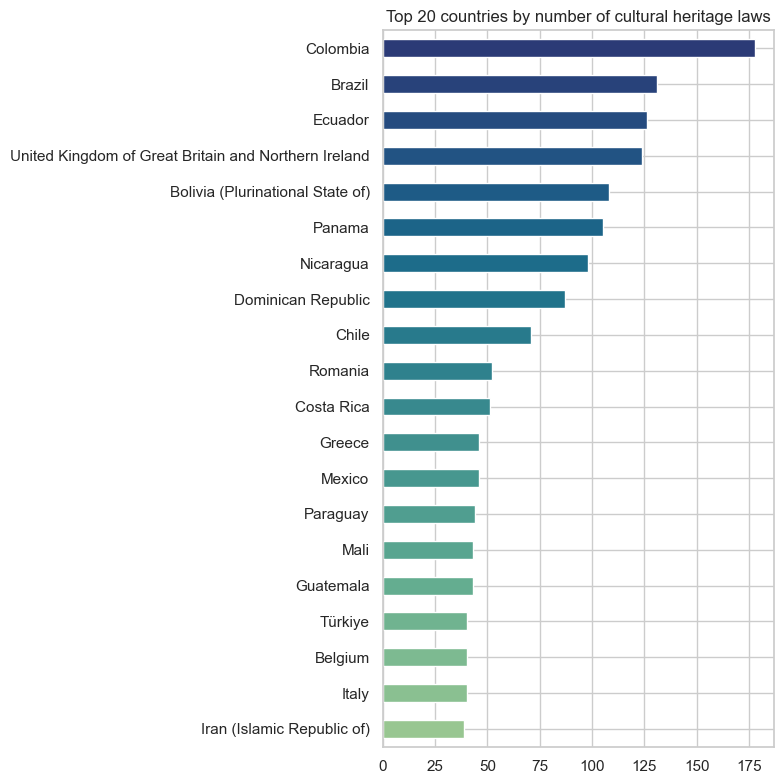

In [11]:
top_countries = df["country"].value_counts().head(20)

fig, ax = plt.subplots(figsize=(8, 8))
top_countries.sort_values().plot(kind="barh", ax=ax, color=sns.color_palette("crest", 20))
ax.set_title("Top 20 countries by number of cultural heritage laws")
plt.tight_layout()
plt.show()

## 10. Geographic distribution

`geo_point_2d` is stored as WKB (well-known binary) point geometry — decode it with `shapely` to get lat/lon.

2761 of 2941 records have coordinates


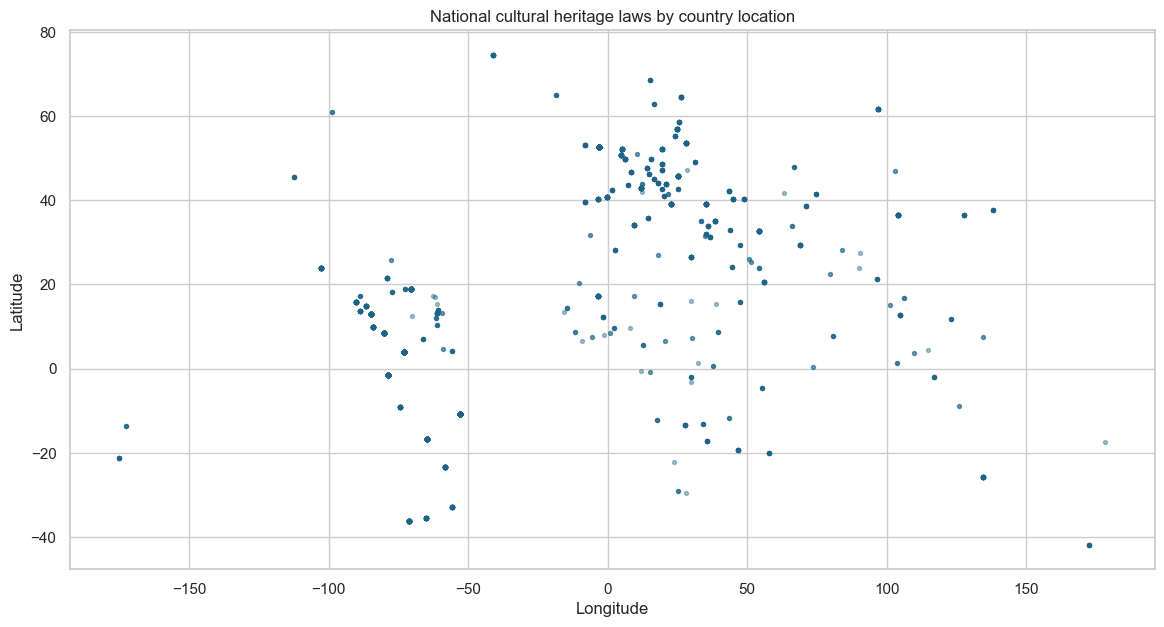

In [12]:
def decode_point(geom):
    if geom is None:
        return pd.Series({"lat": np.nan, "lon": np.nan})
    p = wkb.loads(geom)
    return pd.Series({"lat": p.y, "lon": p.x})

df[["lat", "lon"]] = df["geo_point_2d"].apply(decode_point)
print(f"{df['lat'].notna().sum()} of {len(df)} records have coordinates")

fig, ax = plt.subplots(figsize=(14, 7))
ax.scatter(df["lon"], df["lat"], s=8, alpha=0.4, color=sns.color_palette("crest")[4])
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("National cultural heritage laws by country location")
plt.show()

## 11. Export cleaned data to CSV

In [13]:
output_path = "datasets/mhm001_cleaned.csv"
df = df.drop(columns='geo_point_2d')
df.to_csv(output_path, index=False)
print(f"Saved {len(df)} rows x {df.shape[1]} columns to {output_path}")

Saved 2941 rows x 11 columns to datasets/mhm001_cleaned.csv


## Next steps

Ideas to extend this analysis:
- Cross-reference `terms` (e.g. "Archives", "Art Market", "Archaeological objects or sites") against `categories` to see which legal concepts dominate each heritage type.
- Compare `date` (enactment) vs. `date_application` to measure typical lag before a law takes effect.
- Join against [`whc001`](whc001.ipynb) (World Heritage sites) by country to see whether heritage-rich countries also have more protective legislation.
- Track `date_abrogation` to identify which legal protections have lapsed and when.